**Dataset collection and preprocessing**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler

In [ ]:
# Download the dataset if it doesn't exist
import os
if not os.path.exists("jena_climate_2009_2016.csv"):
    !wget https://s3.amazonaws.com/keras-metadata/jena_climate_2009_2016.csv.zip
    !unzip jena_climate_2009_2016.csv.zip

#Load the dataset
df = pd.read_csv("jena_climate_2009_2016.csv")

print(df.head())
print(df.shape)
print(df.columns)

             Date Time  p (mbar)  T (degC)  Tpot (K)  Tdew (degC)  rh (%)  \
0  01.01.2009 00:10:00    996.52     -8.02    265.40        -8.90    93.3   
1  01.01.2009 00:20:00    996.57     -8.41    265.01        -9.28    93.4   
2  01.01.2009 00:30:00    996.53     -8.51    264.91        -9.31    93.9   
3  01.01.2009 00:40:00    996.51     -8.31    265.12        -9.07    94.2   
4  01.01.2009 00:50:00    996.51     -8.27    265.15        -9.04    94.1   

   VPmax (mbar)  VPact (mbar)  VPdef (mbar)  sh (g/kg)  H2OC (mmol/mol)  \
0          3.33          3.11          0.22       1.94             3.12   
1          3.23          3.02          0.21       1.89             3.03   
2          3.21          3.01          0.20       1.88             3.02   
3          3.26          3.07          0.19       1.92             3.08   
4          3.27          3.08          0.19       1.92             3.09   

   rho (g/m**3)  wv (m/s)  max. wv (m/s)  wd (deg)  
0       1307.75      1.03        

In [ ]:
#Select temperature column
temperature = df["T (degC)"]

print(temperature.head())

0   -8.02
1   -8.41
2   -8.51
3   -8.31
4   -8.27
Name: T (degC), dtype: float64


In [ ]:
#Handle missing values
temperature = temperature.interpolate()

print(temperature.isnull().sum())

0


In [ ]:
#Convert 10-minute readings into hourly readings
df["Date Time"] = pd.to_datetime(df["Date Time"], format='mixed')

df = df.set_index("Date Time")

hourly_temp = df["T (degC)"].resample("1h").mean()

hourly_temp = hourly_temp.interpolate()

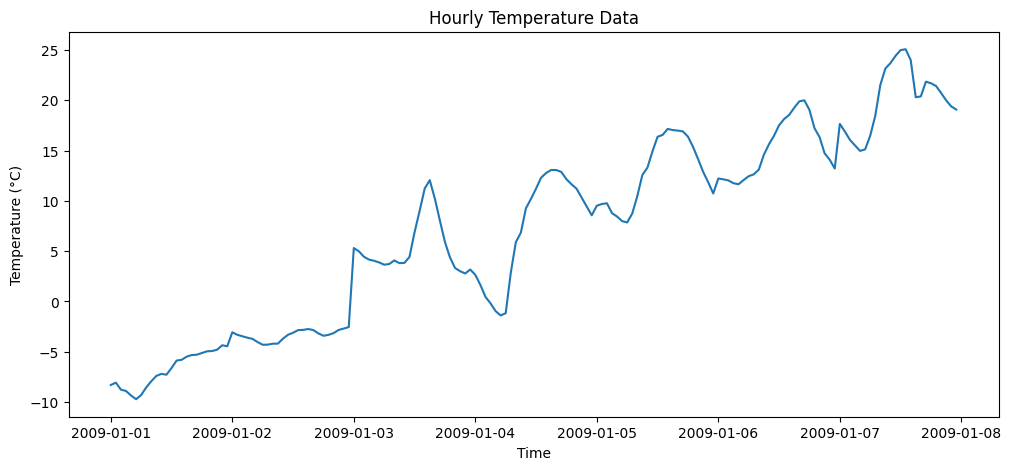

In [ ]:
#Visualize temperature data
plt.figure(figsize=(12,5))

plt.plot(hourly_temp[:168])

plt.title("Hourly Temperature Data")
plt.xlabel("Time")
plt.ylabel("Temperature (°C)")

plt.show()

In [ ]:
hourly_temp.to_csv("processed_temperature.csv")

**LSTM model development**

> Add blockquote



In [ ]:
!pip install tensorflow scikit-learn pandas numpy matplotlib joblib

In [ ]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import MinMaxScaler

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

import joblib

In [ ]:
#Load the processed dataset
df = pd.read_csv("processed_temperature.csv")

data = df.iloc[:, -1].values.reshape(-1, 1)

In [ ]:
#Split the dataset chronologically
n = len(data)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train = data[:train_end]
val = data[train_end:val_end]
test = data[val_end:]

In [ ]:
#Normalize the data
scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(train)

val_scaled = scaler.transform(val)
test_scaled = scaler.transform(test)

joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

In [ ]:
#Create time sequences
def create_sequences(data, window=24):

    X = []
    y = []

    for i in range(window, len(data)):

        X.append(data[i-window:i])
        y.append(data[i])

    return np.array(X), np.array(y)

In [ ]:
#Prepare training and testing data:
X_train, y_train = create_sequences(train_scaled)

X_val, y_val = create_sequences(
    np.concatenate([train_scaled[-24:], val_scaled])
)

X_test, y_test = create_sequences(
    np.concatenate([val_scaled[-24:], test_scaled])
)

In [ ]:
#Build the LSTM model
model = Sequential([
    LSTM(50, input_shape=(24, 1)),
    Dropout(0.2),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mae"]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Train the model
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/10
1534/1534 ━━━━━━━━━━━━━━━━━━━━ 23s 14ms/step - loss: 0.0050 - mae: 0.0489 - val_loss: 9.6892e-04 - val_mae: 0.0208
Epoch 2/10
1534/1534 ━━━━━━━━━━━━━━━━━━━━ 22s 15ms/step - loss: 0.0018 - mae: 0.0307 - val_loss: 0.0010 - val_mae: 0.0229
Epoch 3/10
1534/1534 ━━━━━━━━━━━━━━━━━━━━ 41s 15ms/step - loss: 0.0011 - mae: 0.0230 - val_loss: 5.7660e-04 - val_mae: 0.0161
Epoch 4/10
1534/1534 ━━━━━━━━━━━━━━━━━━━━ 41s 15ms/step - loss: 8.1339e-04 - mae: 0.0181 - val_loss: 4.5456e-04 - val_mae: 0.0118
Epoch 5/10
1534/1534 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - loss: 7.1694e-04 - mae: 0.0164 - val_loss: 4.9419e-04 - val_mae: 0.0129
Epoch 6/10
1534/1534 ━━━━━━━━━━━━━━━━━━━━ 42s 14ms/step - loss: 6.7771e-04 - mae: 0.0156 - val_loss: 4.3449e-04 - val_mae: 0.0110
Epoch 7/10
1534/1534 ━━━━━━━━━━━━━━━━━━━━ 41s 14ms/step - loss: 6.7222e-04 - mae: 0.0154 - val_loss: 4.3340e-04 - val_mae: 0.0107
Epoch 8/10
1534/1534 ━━━━━━━━━━━━━━━━━━━━ 40s 14ms/step - loss: 6.5225e-04 - mae: 0.0152 - val_loss: 4.329

In [ ]:
model.save("lstm_model.keras")

**Testing, evaluation and visualization**

In [ ]:
#Load the trained model
from tensorflow.keras.models import load_model
import joblib
import numpy as np

model = load_model("lstm_model.keras")

scaler = joblib.load("scaler.pkl")

In [ ]:
#Predict temperature
predictions = model.predict(X_test)

predictions = scaler.inverse_transform(predictions)

actual = scaler.inverse_transform(y_test)

329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


In [ ]:
#Calculate MAE and RMSE
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

mae = mean_absolute_error(actual, predictions)

rmse = np.sqrt(
    mean_squared_error(actual, predictions)
)

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 0.6372013196064505
RMSE: 1.1855653429179702


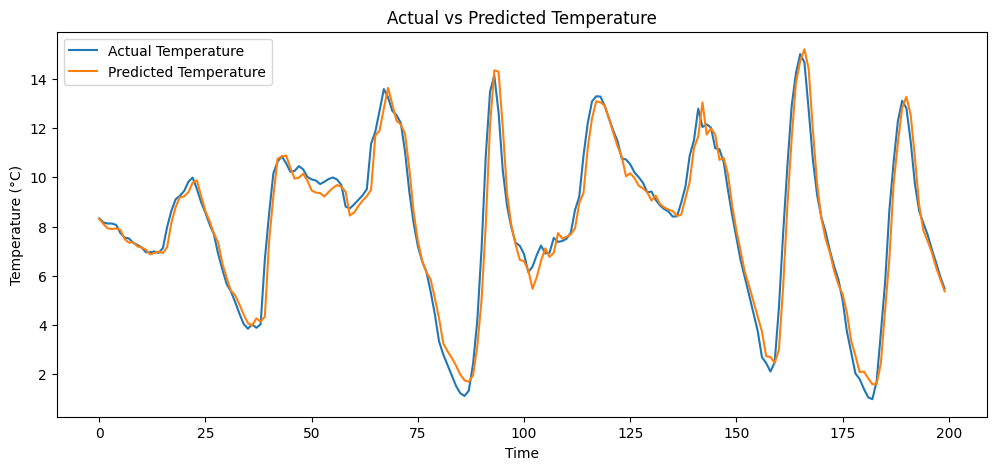

In [ ]:
#Create actual vs predicted graph
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.plot(actual[:200], label="Actual Temperature")

plt.plot(predictions[:200], label="Predicted Temperature")

plt.title("Actual vs Predicted Temperature")

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")

plt.legend()

plt.savefig("prediction_graph.png")

plt.show()

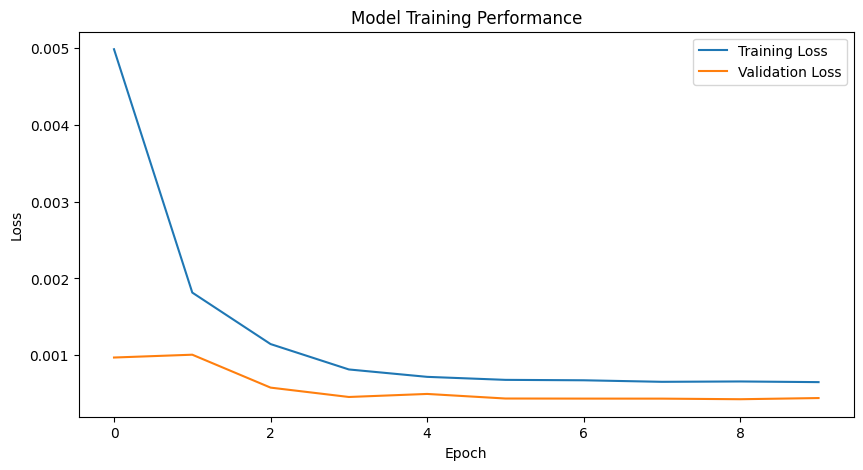

In [ ]:
#Create training and validation loss graph
plt.figure(figsize=(10,5))

plt.plot(history.history["loss"], label="Training Loss")

plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Model Training Performance")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.savefig("training_loss.png")

plt.show()

In [ ]:
#Predict the next hour
last_24 = test_scaled[-24:]

last_24 = last_24.reshape(1, 24, 1)

next_prediction = model.predict(last_24)

next_temperature = scaler.inverse_transform(
    next_prediction
)

print("Next hour temperature:", next_temperature[0][0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
Next hour temperature: -4.585946


**Frontend development and documentation**

In [ ]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 20.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 50.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [ ]:

%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from tensorflow.keras.models import load_model

st.set_page_config(
    page_title="WeatherWise",
    page_icon="🌤️",
    layout="wide"
)

# Title
st.title("🌤️ WeatherWise")
st.subheader("Temperature Prediction Using LSTM")

st.write(
    "A Deep Learning Based Temperature Forecasting System"
)

# Load model and scaler
@st.cache_resource
def load_resources():
    model = load_model("lstm_model.keras")
    scaler = joblib.load("scaler.pkl")
    return model, scaler

model, scaler = load_resources()

# Load dataset
df = pd.read_csv("processed_temperature.csv")

temperature = df.iloc[:, -1].values.reshape(-1, 1)

# Prepare last 24 hours
last_24 = temperature[-24:]

scaled_data = scaler.transform(last_24)

X = scaled_data.reshape(1, 24, 1)

# Prediction
prediction = model.predict(X, verbose=0)

result = scaler.inverse_transform(prediction)[0][0]

# Display prediction
st.markdown("## 🌡️ Predicted Temperature")

st.markdown(
    f"""
    <div style="
        background-color:#17365D;
        padding:25px;
        border-radius:15px;
        text-align:center;
        color:white;">
        <h1 style="font-size:45px;">{result:.2f} °C</h1>
        <p>Next Hour Temperature Prediction</p>
    </div>
    """,
    unsafe_allow_html=True
)

# Historical temperature graph
st.subheader("📈 Historical Temperature")

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(temperature[-168:])

ax.set_title("Last 7 Days Temperature")
ax.set_xlabel("Hourly Readings")
ax.set_ylabel("Temperature (°C)")
ax.grid(True)

st.pyplot(fig)
plt.close(fig)

# Project information
st.subheader("About This Project")

st.write("""
- Deep Learning Model: LSTM
- Dataset: Jena Climate Dataset
- Input: Previous 24 hourly temperature readings
- Output: Next hour temperature prediction
""")

st.success("Temperature prediction completed successfully!")


Overwriting app.py


In [ ]:
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼
added 22 packages in 3s
⠼
⠼3 packages are looking for funding
⠼  run `npm fund` for details
⠼

In [ ]:
!pkill -f streamlit

In [ ]:
!streamlit run app.py --server.address 0.0.0.0 --server.port 8501



2026-10-31 09:47:28.365 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.75.182.222:8501

  Stopping...


In [ ]:
!lt --port 8501

your url is: https://loose-icons-fly.loca.lt
^C


In [ ]:
!curl -s https://loca.lt/mytunnelpassword

34.75.182.222

In [ ]:
!curl -I http://127.0.0.1:8501

HTTP/1.1 200 OK
date: Sat, 31 Oct 2026 09:53:47 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 6467
last-modified: Sat, 31 Oct 2026 09:13:50 GMT
etag: "25544ba9d826e13b79459f989b71a9d9"
cache-control: no-cache



In [ ]:
!nohup streamlit run app.py --server.address 0.0.0.0 --server.port 8501 > streamlit.log 2>&1 &

In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared

In [ ]:
!chmod +x cloudflared

In [ ]:
!./cloudflared tunnel --url http://127.0.0.1:8501

2026-10-31T09:54:34Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-31T09:54:34Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-31T09:54:37Z INF +--------------------------------------------------------------------------------------------+
2026-10-31T09:54:37Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-31T09:54:37Z INF |  https://life-cho-lips-thin.trycloudflare.com         